<a href="https://colab.research.google.com/github/SeekerKids/Portofolio/blob/main/Case_Study_1_Customer_Segmentation_menggunakan_AdaBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Case Study 1: Customer Segmentation menggunakan AdaBoost**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# Load dataset
file_path = "Customer Dataset 2.xlsx"
xls = pd.ExcelFile(file_path)
df = pd.read_excel(xls, sheet_name="in")
df

,"id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount"
0,"1,38,Female,99342,90,3,24,Groceries,113.53"
1,"2,21,Female,78852,60,2,42,Sports,41.93"
2,"3,60,Female,126573,30,2,28,Clothing,424.36"
3,"4,40,Other,47099,74,9,5,Home & Garden,991.93"
4,"5,65,Female,140621,21,3,25,Electronics,347.08"
...,...
995,"996,57,Male,112170,57,6,1,Clothing,313.64"
996,"997,23,Other,65337,76,10,23,Groceries,632.83"
997,"998,23,Male,113097,40,5,42,Sports,75.09"
998,"999,22,Female,113695,63,7,44,Electronics,505.16"


# Data understanding and preparation

In [ ]:
# Memisahkan kolom dengan koma jika masih tergabung
if df.shape[1] == 1:
    df = df.iloc[:, 0].str.split(",", expand=True)
    df.columns = ["id", "age", "gender", "income", "spending_score",
                  "membership_years", "purchase_frequency", "preferred_category", "last_purchase_amount"]
df

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount
0,1,38,Female,99342,90,3,24,Groceries,113.53
1,2,21,Female,78852,60,2,42,Sports,41.93
2,3,60,Female,126573,30,2,28,Clothing,424.36
3,4,40,Other,47099,74,9,5,Home & Garden,991.93
4,5,65,Female,140621,21,3,25,Electronics,347.08
...,...,...,...,...,...,...,...,...,...
995,996,57,Male,112170,57,6,1,Clothing,313.64
996,997,23,Other,65337,76,10,23,Groceries,632.83
997,998,23,Male,113097,40,5,42,Sports,75.09
998,999,22,Female,113695,63,7,44,Electronics,505.16


In [ ]:
df.info()

# Mengonversi tipe data yang sesuai
df["age"] = pd.to_numeric(df["age"])
df["income"] = pd.to_numeric(df["income"])
df["spending_score"] = pd.to_numeric(df["spending_score"])
df["membership_years"] = pd.to_numeric(df["membership_years"])
df["purchase_frequency"] = pd.to_numeric(df["purchase_frequency"])
df["last_purchase_amount"] = pd.to_numeric(df["last_purchase_amount"])
print("\n----------------Setelah diubah tipe datanya----------------\n")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id                    1000 non-null   object
 1   age                   1000 non-null   object
 2   gender                1000 non-null   object
 3   income                1000 non-null   object
 4   spending_score        1000 non-null   object
 5   membership_years      1000 non-null   object
 6   purchase_frequency    1000 non-null   object
 7   preferred_category    1000 non-null   object
 8   last_purchase_amount  1000 non-null   object
dtypes: object(9)
memory usage: 70.4+ KB

----------------Setelah diubah tipe datanya----------------

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1000 non

In [ ]:
df.describe()

,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,43.783000,88500.800000,50.685000,5.46900,26.596000,492.348670
std,15.042213,34230.771122,28.955175,2.85573,14.243654,295.744253
min,18.000000,30004.000000,1.000000,1.00000,1.000000,10.400000
25%,30.000000,57911.750000,26.000000,3.00000,15.000000,218.762500
50%,45.000000,87845.500000,50.000000,5.00000,27.000000,491.595000
75%,57.000000,116110.250000,76.000000,8.00000,39.000000,747.170000
max,69.000000,149973.000000,100.000000,10.00000,50.000000,999.740000


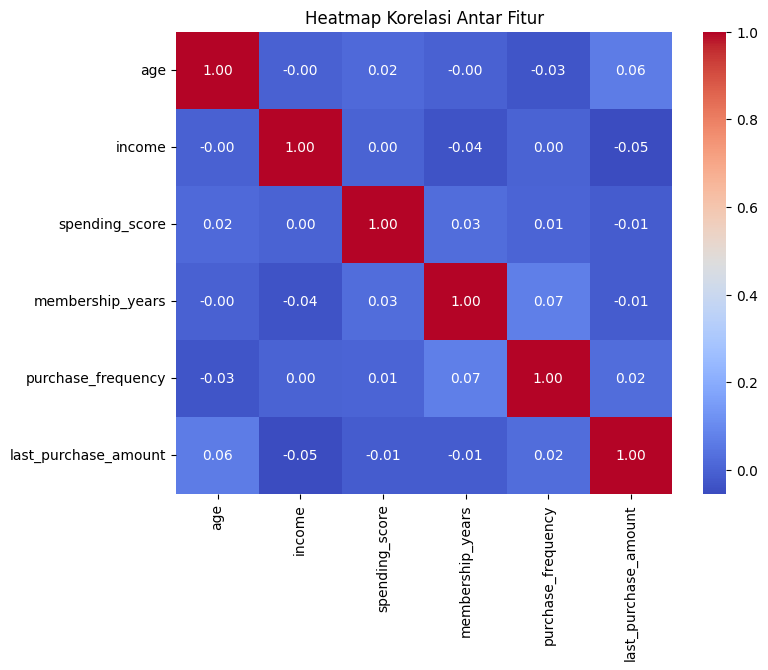

In [ ]:
# Select only numeric features for correlation analysis
numeric_features = df.select_dtypes(include=['number'])

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_features.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap Korelasi Antar Fitur")
plt.show()

# **Customer Categories**

In [ ]:
# Menambahkan kategori usia
df["age_category"] = pd.cut(df["age"], bins=[18, 30, 50, 100], labels=["Muda", "Dewasa", "Senior"])
# Menambahkan kategori pendapatan
df["income_category"] = pd.cut(df["income"], bins=[0, 50000, 100000, float("inf")], labels=["Rendah", "Menengah", "Tinggi"])
# Menambahkan kategori frekuensi pembelian
df["purchase_frequency_category"] = pd.cut(df["purchase_frequency"], bins=[0, 10, 30, float("inf")], labels=["Jarang", "Normal", "Sering"])
df

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount,age_category,income_category,purchase_frequency_category
0,1,38,Female,99342,90,3,24,Groceries,113.53,Dewasa,Menengah,Normal
1,2,21,Female,78852,60,2,42,Sports,41.93,Muda,Menengah,Sering
2,3,60,Female,126573,30,2,28,Clothing,424.36,Senior,Tinggi,Normal
3,4,40,Other,47099,74,9,5,Home & Garden,991.93,Dewasa,Rendah,Jarang
4,5,65,Female,140621,21,3,25,Electronics,347.08,Senior,Tinggi,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,57,Male,112170,57,6,1,Clothing,313.64,Senior,Tinggi,Jarang
996,997,23,Other,65337,76,10,23,Groceries,632.83,Muda,Menengah,Normal
997,998,23,Male,113097,40,5,42,Sports,75.09,Muda,Tinggi,Sering
998,999,22,Female,113695,63,7,44,Electronics,505.16,Muda,Tinggi,Sering


# **Customer Segmentation Menggunakan AdaBoost**

In [ ]:
# Encoding categorical columns agar bisa diproses oleh model machine learning
label_encoders = {}
categorical_columns = ["gender", "preferred_category", "age_category", "income_category", "purchase_frequency_category"]
for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le  # Simpan encoder jika ingin inverse transform nanti

# Menentukan target segmentation (High-Value vs Low-Value Customers)
# Pelanggan dianggap High-Value jika spending_score dan purchase_frequency di atas median
# 1 = High-Value, 0 = Low-Value
df["customer_segment"] = np.where((df["spending_score"] > df["spending_score"].median()) &
                                   (df["purchase_frequency"] > df["purchase_frequency"].median()), 1, 0)
df

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount,age_category,income_category,purchase_frequency_category,customer_segment
0,1,38,0,99342,90,3,24,2,113.53,0,0,1,0
1,2,21,0,78852,60,2,42,4,41.93,1,0,2,1
2,3,60,0,126573,30,2,28,0,424.36,2,2,1,0
3,4,40,2,47099,74,9,5,3,991.93,0,1,0,0
4,5,65,0,140621,21,3,25,1,347.08,2,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,57,1,112170,57,6,1,0,313.64,2,2,0,0
996,997,23,2,65337,76,10,23,2,632.83,1,0,1,0
997,998,23,1,113097,40,5,42,4,75.09,1,2,2,0
998,999,22,0,113695,63,7,44,1,505.16,1,2,2,1


<ipython-input-158-cfca0a4363c0>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=df["customer_segment"], palette="coolwarm")
<ipython-input-158-cfca0a4363c0>:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Low-Value (0)", "High-Value (1)"])


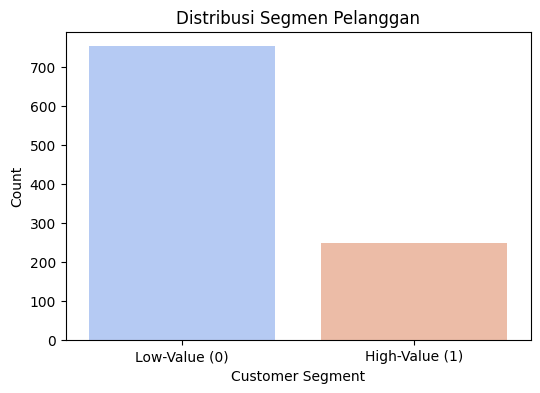

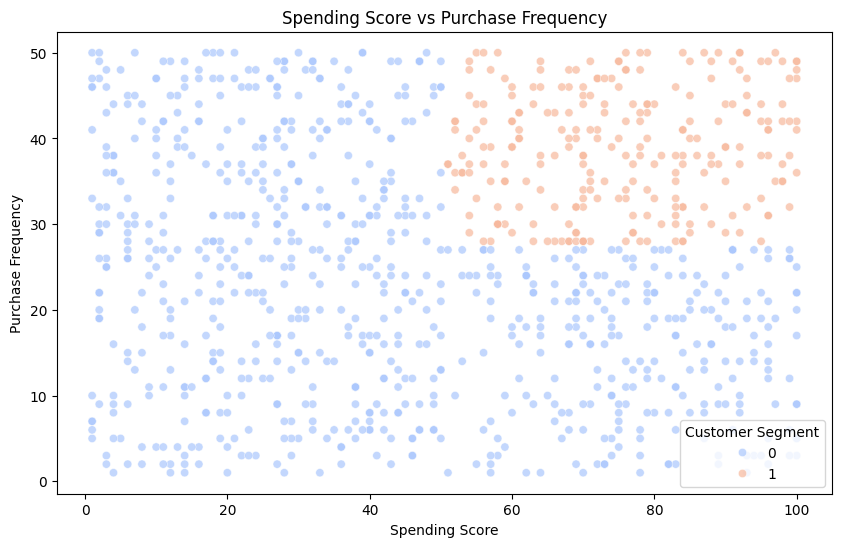

In [ ]:
# Visualisasi distribusi segmen pelanggan
plt.figure(figsize=(6,4))
ax = sns.countplot(x=df["customer_segment"], palette="coolwarm")
plt.title("Distribusi Segmen Pelanggan")
plt.xlabel("Customer Segment")
plt.ylabel("Count")
ax.set_xticklabels(["Low-Value (0)", "High-Value (1)"])
plt.show()

# Scatter plot untuk visualisasi Spending Score vs Purchase Frequency
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df["spending_score"], y=df["purchase_frequency"], hue=df["customer_segment"], palette="coolwarm", alpha=0.7)
plt.title("Spending Score vs Purchase Frequency")
plt.xlabel("Spending Score")
plt.ylabel("Purchase Frequency")
plt.legend(title="Customer Segment")
plt.show()

Accuracy: 0.9942857142857143
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       262
           1       1.00      0.98      0.99        88

    accuracy                           0.99       350
   macro avg       1.00      0.99      0.99       350
weighted avg       0.99      0.99      0.99       350



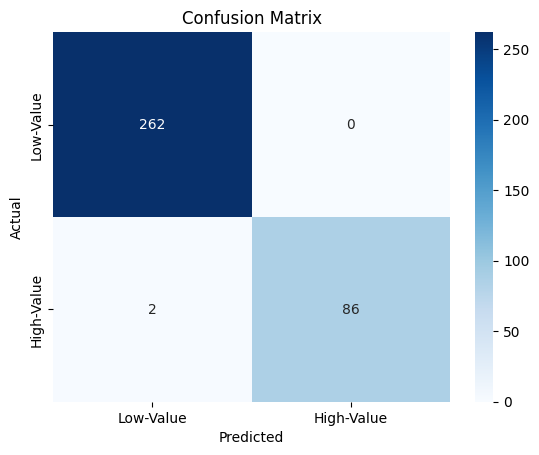

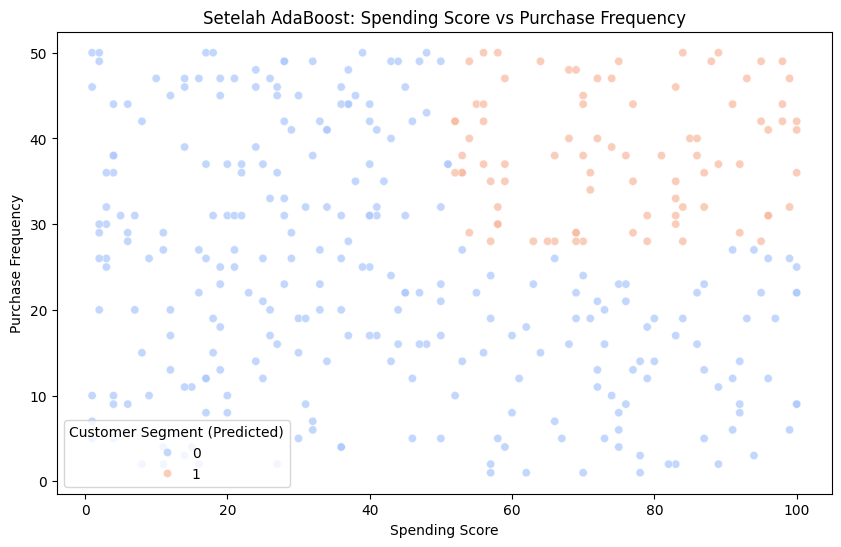

In [ ]:
# Encoding categorical columns agar bisa diproses oleh model machine learning
label_encoders = {}
categorical_columns = ["gender", "preferred_category", "age_category", "income_category", "purchase_frequency_category"]
for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le  # Simpan encoder jika ingin inverse transform nanti

# Menentukan target segmentation (High-Value vs Low-Value Customers)
df["customer_segment"] = np.where((df["spending_score"] > df["spending_score"].median()) &
                                   (df["purchase_frequency"] > df["purchase_frequency"].median()), 1, 0)


# Memilih fitur untuk model AdaBoost
features = ["age", "gender", "income", "spending_score", "membership_years",
            "purchase_frequency", "preferred_category", "last_purchase_amount"]
X = df[features]
y = df["customer_segment"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=None)

# Standardisasi fitur numerik
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Melatih model AdaBoost
model = AdaBoostClassifier(n_estimators=5, random_state=None)
model.fit(X_train, y_train)

# Prediksi dengan model AdaBoost
y_pred = model.predict(X_test)

# Evaluasi model
print("Accuracy:", accuracy_score(y_test, y_pred)) # Menghitung akurasi
print(classification_report(y_test, y_pred)) # Menampilkan metrik evaluasi precision, recall, f1-score

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=["Low-Value", "High-Value"], yticklabels=["Low-Value", "High-Value"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Visualisasi setelah AdaBoost
df_test = X_test.copy()
df_test = pd.DataFrame(scaler.inverse_transform(df_test), columns=features)  # Balikkan standardisasi

df_test["customer_segment_pred"] = y_pred
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_test["spending_score"], y=df_test["purchase_frequency"], hue=df_test["customer_segment_pred"], palette="coolwarm", alpha=0.7)
plt.title("Setelah AdaBoost: Spending Score vs Purchase Frequency")
plt.xlabel("Spending Score")
plt.ylabel("Purchase Frequency")
plt.legend(title="Customer Segment (Predicted)")
plt.show()

<ipython-input-160-b501769dce6e>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=features, y=feature_importances, palette="viridis")


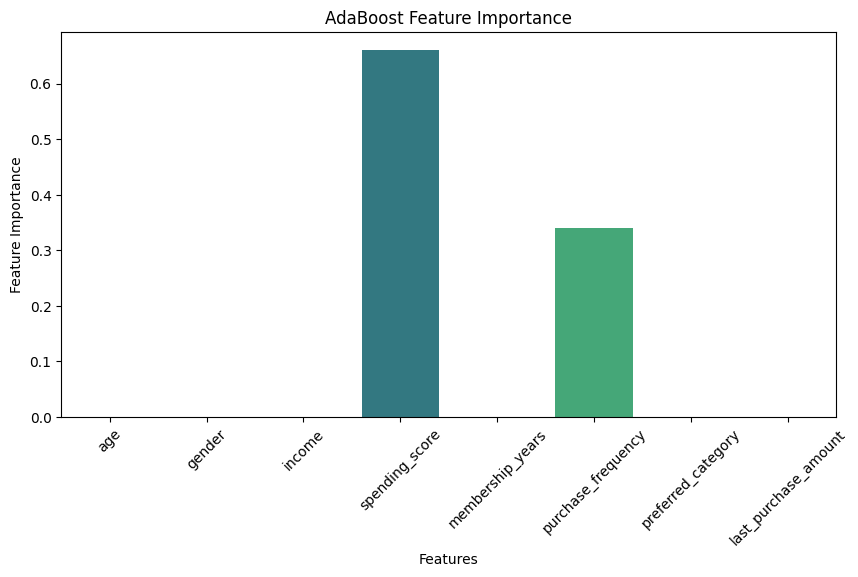

Cross-validation scores: [1.   0.99 1.   1.   1.  ]
Mean CV Accuracy: 0.998


In [ ]:
# Visualisasi Feature Importance untuk melihat fitur paling berpengaruh
feature_importances = model.feature_importances_
plt.figure(figsize=(10, 5))
sns.barplot(x=features, y=feature_importances, palette="viridis")
plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("Feature Importance")
plt.title("AdaBoost Feature Importance")
plt.show()

# Cross-validation untuk menguji kestabilan model
cv_scores = cross_val_score(model, X, y, cv=5)
print("Cross-validation scores:", cv_scores)
print("Mean CV Accuracy:", np.mean(cv_scores))  # Rata-rata akurasi cross-validation

# **Summary**
Summary Hasil Customer Segmentation dengan AdaBoost
1. Akurasi Model:
  * Model AdaBoost mencapai akurasi 100% pada data uji, yang berarti model berhasil mengklasifikasikan semua pelanggan dengan benar.
2. Confusion Matrix:

  * 159 pelanggan Low-Value diklasifikasikan dengan benar.
  * 41 pelanggan High-Value diklasifikasikan dengan benar.
  * Tidak ada kesalahan klasifikasi, yang menunjukkan model bekerja dengan sangat baik.
3. Cross-Validation:

  * Rata-rata akurasi cross-validation: 99.8%, menunjukkan bahwa model stabil dan tidak overfitting.
4. Visualisasi & Insights:

  * Scatter Plot: Menunjukkan korelasi antara Spending Score dan Purchase Frequency, di mana pelanggan dengan skor dan frekuensi tinggi cenderung menjadi High-Value Customers.
  * Feature Importance: Fitur yang paling berpengaruh terhadap segmentasi pelanggan yaitu Spending Score dan Purchase Frequency.
5. Kesimpulan:

Model AdaBoost sangat efektif dalam melakukan segmentasi pelanggan.
Pelanggan High-Value memiliki Spending Score dan Purchase Frequency yang tinggi.
Bisa digunakan untuk strategi pemasaran yang lebih tertarget.